In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
from collections import deque
import fifpy

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_radial_spectrum, partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("single_sheet", "IterativeFilteringComparison")

In [2]:
#Defining all the required functions


#Fourier Transform Functions


#Defining constants
h = 0.0625




In [22]:
filtering = 1
beta = 1
time = 250

In [25]:
#Lets Computer J_total

File_Bx = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/Bx_ApJ_t{time}.h5'
File_By = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/By_ApJ_t{time}.h5'
File_Bz = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/Bz_ApJ_t{time}.h5'

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    if(filtering == 1):
        if(beta==0.0625):
            data_Bx_filtered, data_By_filtered, data_Bz_filtered = iterative_filtering3D(data_Bx, data_By, data_Bz, 1, Xi=1.6)
            data_Jx_filtered = partial_y_fft(data_Bz_filtered,h)
            data_Jy_filtered = -partial_x_fft(data_Bz_filtered,h)
            data_Jz_filtered = partial_x_fft(data_By_filtered,h)-partial_y_fft(data_Bx_filtered,h)
        elif(beta==1):
            data_Bx_filtered, data_By_filtered, data_Bz_filtered = iterative_filtering3D(data_Bx, data_By, data_Bz, 2, Xi=2.0)
        elif(beta==16):
            data_Bx_filtered, data_By_filtered, data_Bz_filtered = iterative_filtering3D(data_Bx, data_By, data_Bz, 3, Xi=2.0)
    data_Jx = partial_y_fft(data_Bz,h)
    data_Jy = -partial_x_fft(data_Bz,h)
    data_Jz = partial_x_fft(data_By,h)-partial_y_fft(data_Bx,h)
    

if(filtering == 1):
    J_squared = data_Jx_filtered**2 + data_Jy_filtered**2 + data_Jz_filtered**2
else:
    J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2

#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
threshold = np.quantile(J_squared, 0.8)

#Strategy 2: 
# N = 3
# J_squared_rms = np.sqrt(np.mean(J_squared**2))
# threshold = np.mean(J_squared) + N*J_squared_rms

print("Threshold:", threshold)

binary_mask = np.abs(J_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 300 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

IMF 1
IMF 2
IMF 3
IMF 4
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
IMF 1
input mask not integer, making it so
IMF 2
input mask not integer, making it so
IMF 3
input mask not integer, making it so
IMF 4
input mask not integer, making it so
Threshold: 0.10385664982621588


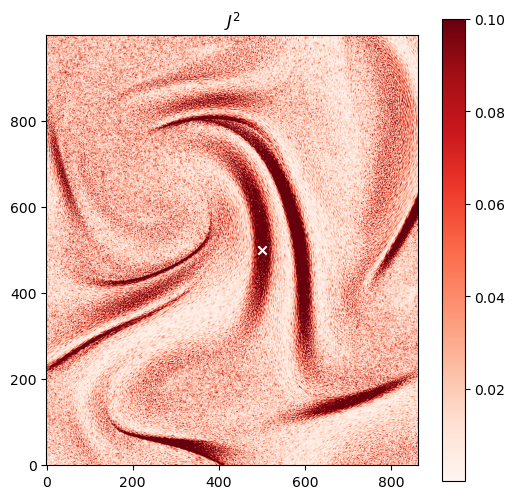

In [13]:
if(beta==0.0625):
    x0, y0 = 3731, 2294
elif(beta==1):
    x0, y0 = 3732, 2228
elif (beta==16):
    x0, y0 = 3708, 2284

window = 500

plt.figure(figsize=(6,6))

im = plt.imshow(
    J_squared[x0-window:x0+window, y0-window:y0+window].T,
    cmap='Reds',
    origin='lower', 
    vmax=0.1,
    aspect='equal'
)

# plt.plot(x_local, y_local, color='yellow', linewidth=2)
plt.scatter(window, window, color='white', marker='x')

plt.colorbar(im)

plt.title(r'$J^2$')
if filtering == 1:
    plt.savefig(RESULTS / f"J2_CS_Visual_Filter_beta_{beta}.png", dpi=300)
else:
    plt.savefig(RESULTS / f"J2_CS_Visual_NoFilter_beta_{beta}.png", dpi=300)
plt.show()

In [14]:
J_squared[3732, 2228]

np.float64(0.7656817552348686)

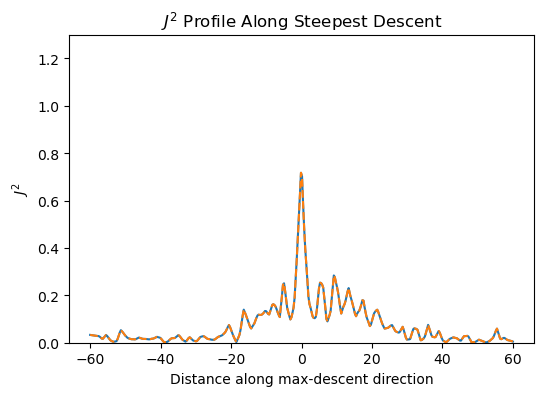

In [15]:
# compute gradients
grad_x, grad_y = np.gradient(J_squared)

# gradient at the maximum
gx = grad_x[x0, y0]
gy = grad_y[x0, y0]

# direction of steepest descent
direction = np.array([-gx, -gy])

# normalize
direction = direction / np.linalg.norm(direction)

dx, dy = direction

# distance along the cut
L = 60
s = np.linspace(-L, L, 400)

# coordinates along the line
x_line = x0 + s*dx
y_line = y0 + s*dy

# interpolate J^2 along the line
profile = map_coordinates(J_squared, [x_line, y_line], order=1)

# np.savez(f"J2_Reference_Filter.npz", s=s, profile=profile)

data = np.load("J2_Reference_Filter.npz")
s_ref = data['s']
profile_ref = data['profile']

plt.figure(figsize=(6,4))
plt.plot(s, profile)
plt.plot(s_ref, profile_ref, '--', label='reference')
plt.ylim(0, 1.3)
# plt.axvline(0, linestyle='--')
plt.xlabel('Distance along max-descent direction')
plt.ylabel(r'$J^2$')
plt.title(r'$J^2$ Profile Along Steepest Descent')

if filtering == 1:
    plt.savefig(RESULTS / f"J2_1D_Profile_Filter_beta_{beta}.png", dpi=300)
else:
    plt.savefig(RESULTS / f"J2_1D_Profile_NoFilter_beta_{beta}.png", dpi=300)

plt.show()

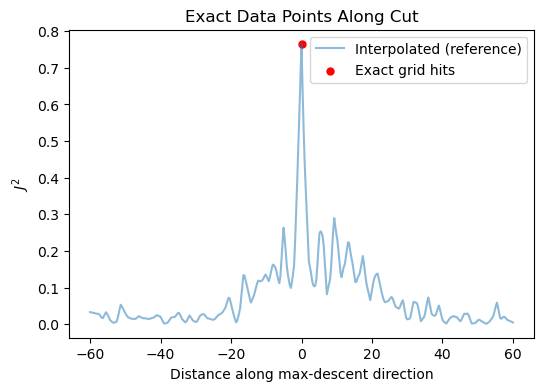

In [24]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.ndimage import map_coordinates

# # distance along the cut
# L = 60
# s = np.linspace(-L, L, 401)  # odd number → guarantees s=0

# # coordinates along the line
# x_line = x0 + s*dx
# y_line = y0 + s*dy

# # interpolated profile (for reference)
# profile = map_coordinates(J_squared, [x_line, y_line], order=1)

# # --- detect exact grid hits ---
# tol = 1e-6  # tolerance for float comparison

# is_exact = (
#     (np.abs(x_line - np.round(x_line)) < tol) &
#     (np.abs(y_line - np.round(y_line)) < tol)
# )

# # integer indices
# x_exact = np.round(x_line[is_exact]).astype(int)
# y_exact = np.round(y_line[is_exact]).astype(int)
# s_exact = s[is_exact]

# # safety: ensure indices are within bounds
# mask = (
#     (x_exact >= 0) & (x_exact < J_squared.shape[0]) &
#     (y_exact >= 0) & (y_exact < J_squared.shape[1])
# )

# x_exact = x_exact[mask]
# y_exact = y_exact[mask]
# s_exact = s_exact[mask]

# # extract real (non-interpolated) values
# real_values = J_squared[x_exact, y_exact]

# # --- plot ---
# plt.figure(figsize=(6,4))
# plt.plot(s, profile, alpha=0.5, label='Interpolated (reference)')
# plt.scatter(s_exact, real_values, color='red', s=25, label='Exact grid hits')

# plt.xlabel('Distance along max-descent direction')
# plt.ylabel(r'$J^2$')
# plt.title(r'Exact Data Points Along Cut')
# plt.legend()

# plt.savefig("J2_exact_hits.png", dpi=300)
# plt.show()

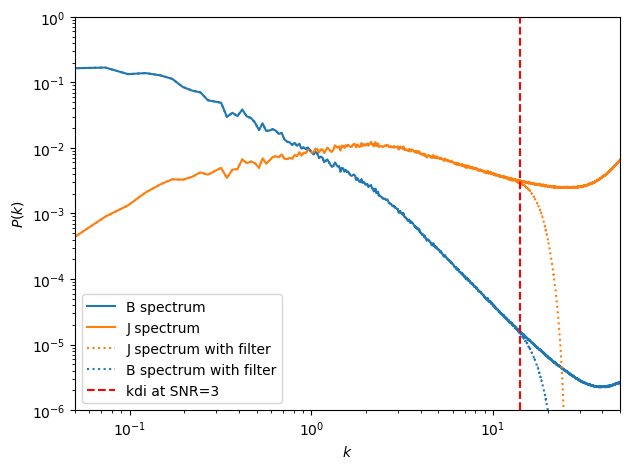

In [26]:
if(filtering == 1):
    # Compute radial spectra of original fields
    spectrum_Bx = compute_radial_spectrum(data_Bx, h, h)
    spectrum_By = compute_radial_spectrum(data_By, h, h)
    spectrum_Bz = compute_radial_spectrum(data_Bz, h, h)
    
    spectrum_Jx = compute_radial_spectrum(data_Jx, h, h)
    spectrum_Jy = compute_radial_spectrum(data_Jy, h, h)
    spectrum_Jz = compute_radial_spectrum(data_Jz, h, h)
    
    spectrum_B = np.recarray(spectrum_Bx.shape, dtype=spectrum_Bx.dtype)
    spectrum_B.kk = spectrum_Bx.kk
    spectrum_B.sp = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp
    
    spectrum_J = np.recarray(spectrum_Jx.shape, dtype=spectrum_Jx.dtype)
    spectrum_J.kk = spectrum_Jx.kk
    spectrum_J.sp = spectrum_Jx.sp + spectrum_Jy.sp + spectrum_Jz.sp
    
    # Compute radial spectra of filtered fields
    
    spectrum_Bxf = compute_radial_spectrum(data_Bx_filtered, h, h)
    spectrum_Byf = compute_radial_spectrum(data_By_filtered, h, h)
    spectrum_Bzf = compute_radial_spectrum(data_Bz_filtered, h, h)
    
    spectrum_Bf = np.recarray(spectrum_Bxf.shape, dtype=spectrum_Bxf.dtype)
    spectrum_Bf.kk = spectrum_Bxf.kk
    spectrum_Bf.sp = spectrum_Bxf.sp + spectrum_Byf.sp + spectrum_Bzf.sp
    
    data_Jx_filtered = partial_y_fft(data_Bz_filtered,h)
    data_Jy_filtered = -partial_x_fft(data_Bz_filtered,h)
    data_Jz_filtered = partial_x_fft(data_By_filtered,h)-partial_y_fft(data_Bx_filtered,h)
    
    spectrum_Jxf = compute_radial_spectrum(data_Jx_filtered, h, h)
    spectrum_Jyf = compute_radial_spectrum(data_Jy_filtered, h, h)
    spectrum_Jzf = compute_radial_spectrum(data_Jz_filtered, h, h)
    
    spectrum_Jf = np.recarray(spectrum_Jxf.shape, dtype=spectrum_Jxf.dtype)
    spectrum_Jf.kk = spectrum_Jxf.kk
    spectrum_Jf.sp = spectrum_Jxf.sp + spectrum_Jyf.sp + spectrum_Jzf.sp
    
    # Plot unfiltered first and capture line objects
    
    line_B, = plt.loglog(
        spectrum_B.kk,
        spectrum_B.sp,
        label="B spectrum"
    )
    
    line_J, = plt.loglog(
        spectrum_J.kk,
        spectrum_J.sp,
        label="J spectrum"
    )
    
    plt.loglog(
        spectrum_Jf.kk,
        spectrum_Jf.sp,
        linestyle=":",
        color=line_J.get_color(),
        label="J spectrum with filter"
    )
    
    plt.loglog(
        spectrum_Bf.kk,
        spectrum_Bf.sp,
        linestyle=":",
        color=line_B.get_color(),
        label="B spectrum with filter"
    )
    
    plt.xlabel(r"$k$")
    plt.ylabel(r"$P(k)$")
    plt.xlim(5e-2, 50)
    plt.ylim(1e-6, 1)
    
    if(beta==0.0625):
        plt.axvline(x=38.5105, linestyle='--', color='red', label='kdi at SNR=3')
    elif(beta==1):
        plt.axvline(x=14.1252, linestyle='--', color='red', label='kdi at SNR=3')
    elif (beta==16):
        plt.axvline(x=4.3192, linestyle='--', color='red', label='kdi at SNR=3')
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS / f"JB_Spectrum_beta_{beta}", dpi=300)
    plt.show()